# 2. Delay patterns

When are Iranian domestic departures late, by how much, and what predicts it? This notebook explores the 3,574 training departures and motivates the features in `aeroscrape.features.build`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import nbutils
from nbutils import BLUE, GREEN, GREY, ORANGE, RED

nbutils.setup()

In [2]:
from aeroscrape.data.clean import select_training_rows
from aeroscrape.features.preprocess import make_model_frame

flights, _ = nbutils.load_flights()
config = nbutils.project_config()
frame = make_model_frame(flights, config)
delay = frame["delay_minutes"]
print(f"{len(frame):,} departures; median delay {delay.median():.0f} min; {(delay > 15).mean():.0%} more than 15 minutes late")

Ignoring 3 implausible delays outside [-60, 720] min


3,574 departures; median delay 20 min; 59% more than 15 minutes late


## The delay distribution is skewed

10%      2.0
50%     20.0
90%     75.0
99%    254.0


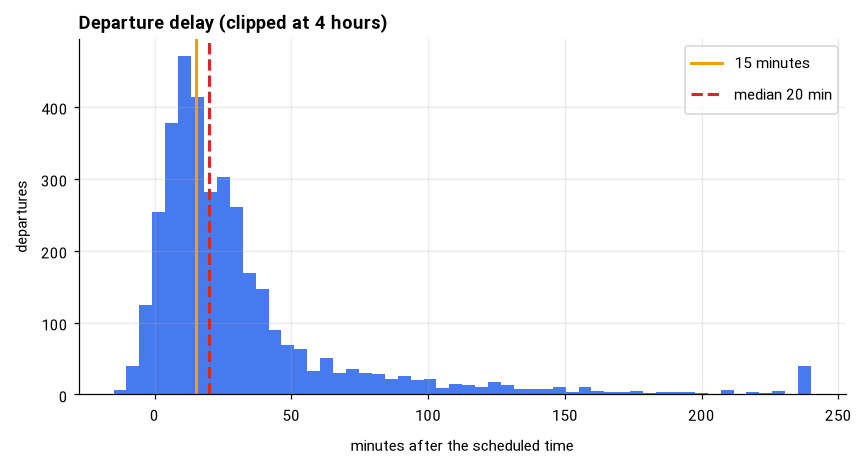

In [3]:
fig, ax = plt.subplots()
ax.hist(delay.clip(-30, 240), bins=54, color=BLUE, alpha=0.85)
ax.axvline(15, color=ORANGE, lw=2, label="15 minutes")
ax.axvline(delay.median(), color=RED, lw=2, ls="--", label=f"median {delay.median():.0f} min")
ax.set_title("Departure delay (clipped at 4 hours)")
ax.set_xlabel("minutes after the scheduled time")
ax.set_ylabel("departures")
ax.legend()
print(delay.quantile([0.1, 0.5, 0.9, 0.99]).round(0).rename(lambda q: f"{q:.0%}").to_string())

Half the flights leave within about 20 minutes, but one in ten is more than an hour and a quarter late and the tail runs to several hours. A single predicted number of minutes would be far off for many flights, which is why the model returns a probability and a 10–90% range instead.

## Time of day and day of week

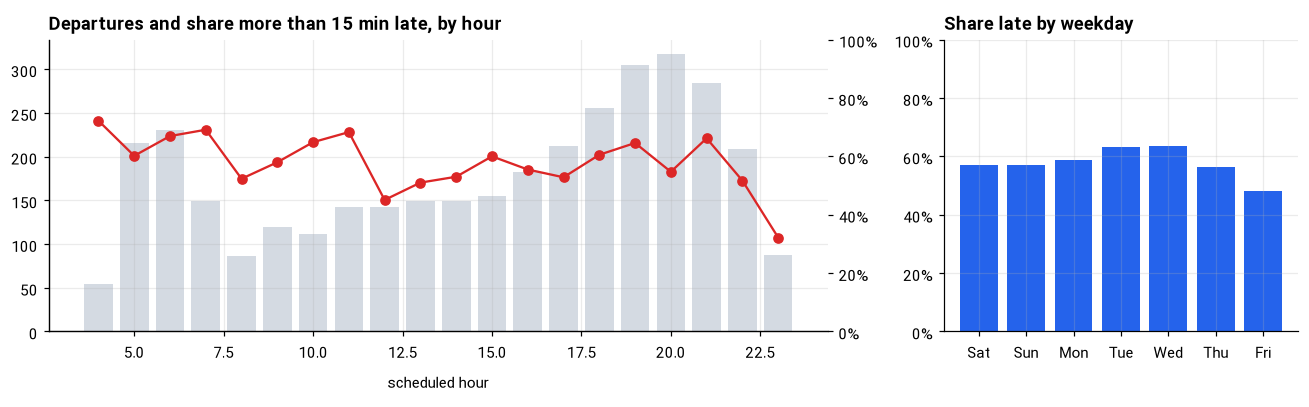

In [4]:
delayed = frame.assign(late=frame["delay_minutes"] > 15)
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
hourly = delayed.groupby("Scheduled_Hour_of_Day")["late"].agg(["mean", "size"])
hourly = hourly[hourly["size"] >= 30]  # a few night hours have a handful of flights
left.bar(hourly.index, hourly["size"], color=GREY, alpha=0.4, label="departures")
twin = left.twinx()
twin.plot(hourly.index, hourly["mean"], color=RED, marker="o", label="share late")
twin.set_ylim(0, 1)
twin.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
twin.grid(False)
left.set_title("Departures and share more than 15 min late, by hour")
left.set_xlabel("scheduled hour")
week = ["Saturday", "Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]  # the Iranian week
weekday = delayed.groupby("scheduled_day_of_week")["late"].mean().reindex(week)
right.bar(range(7), weekday.values, color=BLUE)
right.set_xticks(range(7), [d[:3] for d in week])
right.set_ylim(0, 1)
right.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
right.set_title("Share late by weekday")
plt.tight_layout()

The share of late departures moves between 45% and 72% through the day: highest in the early-morning bank (4 to 7 am), lowest around noon and for the last flights at night. Friday, the Iranian weekend, is the calmest day. Time and day matter much less than the airline, below.

## Airlines differ more than anything else

,late,flights,median
airline,,,
اطلس ایر,0.76,86,33.0
آتا,0.76,520,30.0
زاگرس,0.74,151,25.0
قشم ایر,0.71,115,24.0
تابان,0.69,51,31.0
پارس ایر,0.64,75,22.0
وارش,0.62,186,24.5
کیش ایر,0.62,195,22.0
ایران ایرتور,0.62,207,20.0


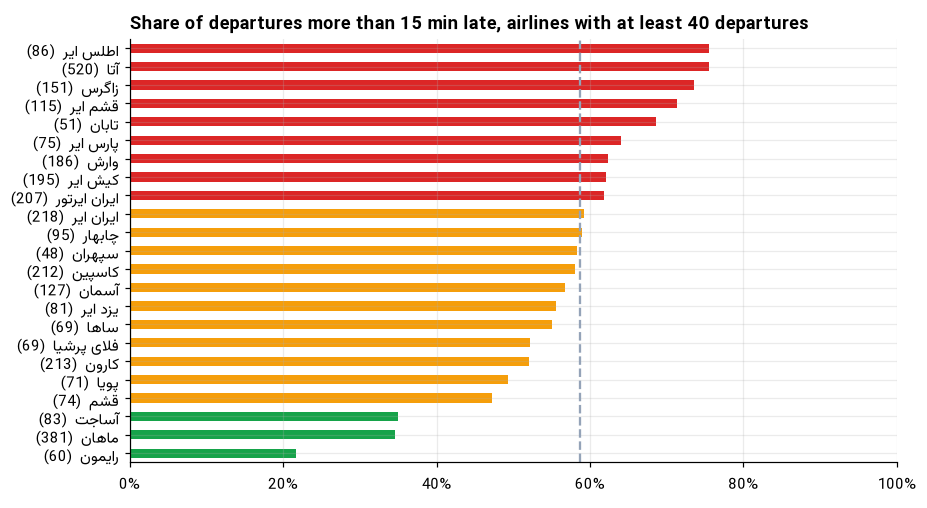

In [5]:
by_airline = delayed.groupby("airline").agg(late=("late", "mean"), flights=("late", "size"), median=("delay_minutes", "median"))
by_airline = by_airline[by_airline["flights"] >= 40].sort_values("late")
ax = by_airline["late"].plot.barh(color=[RED if v > 0.6 else ORANGE if v > 0.4 else GREEN for v in by_airline["late"]], figsize=(9, 5))
ax.set_yticklabels([f"{a}  ({n})" for a, n in zip(by_airline.index, by_airline["flights"])])
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.axvline(delayed["late"].mean(), color=GREY, ls="--")
ax.set_title("Share of departures more than 15 min late, airlines with at least 40 departures")
by_airline.sort_values("late", ascending=False).round(2)

From 22% of departures late (رایمون) to 76% (آتا, اطلس ایر): the spread between airlines is far wider than between hours or weekdays. That is why the baseline the model has to beat is the airline's own delay rate, and why airline identity carries most of what the 7-day rate features would say.

## Delays propagate through the aircraft's day

Previous delay known for 30% of departures


prev_departure_delay_min    0.37
airline_delay_rate_7d       0.17
Scheduled_Hour_of_Day      -0.04
scheduled_turnaround_min    0.01
Name: delay_minutes, dtype: float64

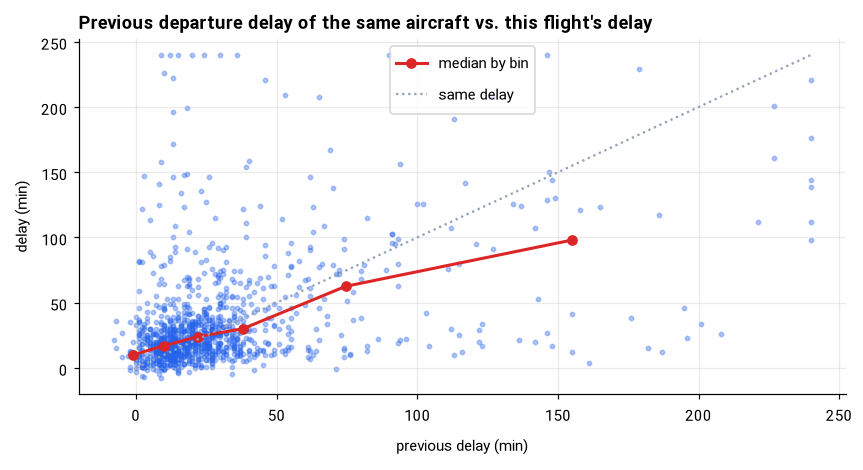

In [6]:
known = frame[frame["prev_departure_delay_min"].notna()]
fig, ax = plt.subplots()
ax.scatter(known["prev_departure_delay_min"].clip(-30, 240), known["delay_minutes"].clip(-30, 240), s=8, alpha=0.35, color=BLUE)
bins = pd.cut(known["prev_departure_delay_min"], [-60, 0, 15, 30, 60, 120, 720])
means = known.groupby(bins, observed=True).agg(x=("prev_departure_delay_min", "median"), y=("delay_minutes", "median"))
ax.plot(means["x"], means["y"], color=RED, marker="o", lw=2, label="median by bin")
ax.plot([0, 240], [0, 240], color=GREY, ls=":", label="same delay")
ax.set_title("Previous departure delay of the same aircraft vs. this flight's delay")
ax.set_xlabel("previous delay (min)")
ax.set_ylabel("delay (min)")
ax.legend()
# inbound_delay_min is left out: the 2025 boards published no landing times at Mehrabad
corr = frame[["delay_minutes", "prev_departure_delay_min", "scheduled_turnaround_min", "Scheduled_Hour_of_Day", "airline_delay_rate_7d"]].corr()["delay_minutes"].drop("delay_minutes")
print(f"Previous delay known for {len(known) / len(frame):.0%} of departures")
corr.sort_values(key=abs, ascending=False).round(2)

## Takeaways

- Delays are frequent and heavy-tailed: a probability and a range describe them better than one number.
- The airline is the strongest static signal; time of day and weekday matter less.
- The aircraft's previous delay is the strongest single predictor (correlation 0.37, against 0.17 for the airline's recent delay rate), and a delay is mostly passed on, partly recovered. But it is known for only 30% of departures, because registrations are almost only published at Mehrabad.